**Сначала переключитесь на графический процессор!**

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Все задания выполнены с исходными параметрами преподавателя: CIFAR-10 загружается `torchvision.datasets.CIFAR10`,
> подвыборки — 10 000 обучающих и 2 000 валидационных изображений, весь тест (10 000); в экспериментах 1–5 — до
> 20 эпох с ранней остановкой (`patience = 5`), в итоговом эксперименте 6 — до 50 эпох с `patience = 7`.
> Выполнены задания: инициализация по умолчанию, Dropout > 0,5 (0,7; 0,9; 1,0), дополнительные размеры батча
> (32 и 128), отражение относительно горизонтальной оси, вопрос про 0,5109; выводы — после каждого эксперимента.
>
> Технические изменения: устройство выбирается в первой ячейке кода (cuda → mps → cpu); лучшие веса при ранней
> остановке хранятся в памяти (копия `state_dict`), а не в файле `best_model.pth`; интерактивные графики plotly
> продублированы статичными копиями (функция `plotly_static`), чтобы результаты были видны и без запущенного Jupyter.

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


# Практикум: MLP на CIFAR-10 — исследование регуляризации и гиперпараметров

😊 **Шутка:** CIFAR-10 — это как коробка с 10 разными игрушками. Наша задача — научить MLP (многослойный перцептрон) их различать, хотя он и не видит картинку целиком, а только длинный вектор.

👆 **На пальцах:** Сегодня мы проведём серию экспериментов, чтобы понять, как разные техники влияют на обучение сети. Мы будем менять инициализацию, добавлять нормализацию, dropout, менять размер батча, применять аугментацию и раннюю остановку. Все это поможет нам бороться с переобучением и улучшать качество.

**Важно:** Мы используем только полносвязные слои (MLP), без свёрток. Это заведомо не самая лучшая архитектура для картинок, но она отлично подходит для демонстрации эффектов регуляризации.

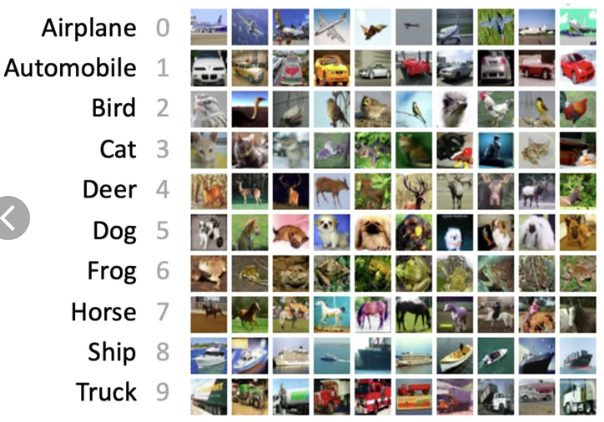

In [2]:
# Импорты и настройки
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
import time


pio.renderers.default = "plotly_mimetype+notebook_connected"
EPOCHS = S(20, 1)                                 # число эпох в экспериментах 1–5, как в задании

def plotly_static(fig):
    """Статичная копия линейного plotly-графика (go.Scatter, в т. ч. в make_subplots) средствами matplotlib:
    интерактивный график виден только в запущенном Jupyter, а эта копия сохраняется в файле как картинка."""
    keys = sorted({t.xaxis or 'x' for t in fig.data}, key=lambda k: int(k[1:] or 1))
    f, axs = plt.subplots(1, len(keys), figsize=(6.5 * len(keys), 4.2), squeeze=False)
    axs = axs[0]
    for t in fig.data:
        ax = axs[keys.index(t.xaxis or 'x')]
        y = np.asarray(t.y, dtype=float)
        x = np.asarray(t.x) if t.x is not None else np.arange(len(y))
        dash = t.line is not None and t.line.dash in ('dash', 'dot')
        ax.plot(x, y, '--' if dash else '-', color=(t.line.color if t.line is not None else None), label=t.name, lw=1.6)
    titles = [a.text for a in (fig.layout.annotations or [])]
    for i, ax in enumerate(axs):
        lx, ly = fig.layout['xaxis' if i == 0 else f'xaxis{i + 1}'], fig.layout['yaxis' if i == 0 else f'yaxis{i + 1}']
        if lx is not None and lx.title.text: ax.set_xlabel(lx.title.text)
        if ly is not None and ly.title.text: ax.set_ylabel(ly.title.text)
        if i < len(titles): ax.set_title(titles[i])
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    if fig.layout.title.text:
        (axs[0].set_title if len(axs) == 1 else f.suptitle)(fig.layout.title.text)
    f.tight_layout(); plt.show()

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

# Устройство
device = get_device()
print(f'Using device: {device}')

Using device: mps


In [3]:
# Загрузка данных CIFAR-10
# Для ускорения возьмём подвыборку (первые 10000 обучающих, 2000 тестовых)
# Но можно и полный датасет, если есть время.

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

train_full = datasets.CIFAR10(DATA, train=True, download=True, transform=transform)
test_full = datasets.CIFAR10(DATA, train=False, download=True, transform=transform)

# Для экспериментов возьмём подвыборку (ускорит обучение)
num_train = S(10000, 256)
num_val = S(2000, 128)
indices = torch.randperm(len(train_full))
train_indices = indices[:num_train]
val_indices = indices[num_train:num_train+num_val]

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(train_full, val_indices)
test_dataset = test_full if not SMOKE else Subset(test_full, range(256))

print(f'Train samples: {len(train_dataset)}')
print(f'Val samples: {len(val_dataset)}')
print(f'Test samples: {len(test_dataset)}')
print('Классы в обучающей подвыборке:', np.bincount(np.array(train_full.targets)[train_indices.numpy()], minlength=10).tolist())

Train samples: 10000
Val samples: 2000
Test samples: 10000
Классы в обучающей подвыборке: [1024, 996, 983, 990, 995, 981, 1029, 1022, 980, 1000]


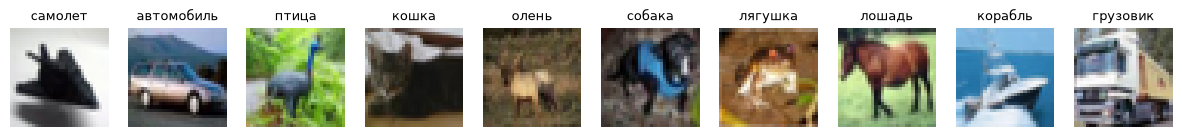

In [4]:
# Как выглядят данные (по одному изображению каждого класса)
class_names = ['самолет', 'автомобиль', 'птица', 'кошка', 'олень', 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']
raw = datasets.CIFAR10(DATA, train=True)
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c, ax in enumerate(axes):
    i = raw.targets.index(c)
    ax.imshow(raw.data[i]); ax.set_title(class_names[c], fontsize=9); ax.axis('off')
plt.show()

## Определим модель MLP с настраиваемыми параметрами

Мы будем использовать сеть с тремя скрытыми слоями. Можно будет включать/выключать BatchNorm, Dropout, выбирать тип инициализации.

👆 **На пальцах:** Наша модель — это три полносвязных слоя с ReLU. После каждого слоя (кроме последнего) мы можем поставить BatchNorm и Dropout.

In [5]:
class MLP(nn.Module):
    def __init__(self, input_dim=3072, hidden_dims=[512, 256, 128], output_dim=10,
                 use_bn=False, dropout_rate=0.0, init_type='xavier'):
        super().__init__()
        self.use_bn = use_bn
        layers = []
        prev_dim = input_dim

        for i, h_dim in enumerate(hidden_dims):
            layers.append(nn.Linear(prev_dim, h_dim))
            if use_bn:
                layers.append(nn.BatchNorm1d(h_dim))
            layers.append(nn.ReLU())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            prev_dim = h_dim

        layers.append(nn.Linear(prev_dim, output_dim))
        self.net = nn.Sequential(*layers)

        self._initialize_weights(init_type)

    def _initialize_weights(self, init_type):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                if init_type == 'default':
                    continue  # оставляем инициализацию PyTorch (Kaiming uniform с a=sqrt(5)) и для весов, и для смещений
                elif init_type == 'zeros':
                    nn.init.zeros_(m.weight)
                elif init_type == 'normal':
                    nn.init.normal_(m.weight, mean=0, std=1)
                elif init_type == 'xavier':
                    nn.init.xavier_uniform_(m.weight)
                elif init_type == 'he':
                    nn.init.kaiming_uniform_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        # x: (batch, 3, 32, 32) -> (batch, 3072)
        x = x.view(x.size(0), -1)
        return self.net(x)

## Функция обучения с early stopping

Мы будем обучать модель заданное число эпох, но останавливаться, если валидационная потеря не улучшается в течение `patience` эпох. Лучшие веса сохраняются.

In [6]:
def train_model(model, train_loader, val_loader, epochs=50, lr=0.001, patience=5, verbose=True):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    best_val_loss = float('inf')
    best_epoch = 0
    trigger_times = 0
    best_state = copy.deepcopy(model.state_dict())
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    t0 = time.perf_counter()

    for epoch in range(epochs):
        # Обучение
        model.train()
        train_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
        train_loss /= len(train_loader.dataset)
        history['train_loss'].append(train_loss)

        # Валидация
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / total
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if verbose:
            print(f'Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}')

        # Early stopping (лучшие веса храним в памяти, а не в файле best_model.pth)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            trigger_times = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            trigger_times += 1
            if trigger_times >= patience:
                print(f'Early stopping at epoch {epoch+1}')
                break

    # Загружаем лучшую модель
    model.load_state_dict(best_state)
    history['time'] = time.perf_counter() - t0
    return model, history, best_epoch

## Эксперимент 1: Сравнение инициализаций

Проверим, как ведёт себя сеть с разными инициализациями: zeros, normal, xavier, he.
Ожидаем, что нулевая совсем не обучается, normal может взрываться, xavier и he дадут нормальное обучение.

Используем фиксированные гиперпараметры: без BN, без dropout, batch size = 64, 20 эпох.

**Задание: добавить инициализацию по-умолчанию.**


=== Инициализация: zeros ===


Early stopping at epoch 6
Best val acc: 0.1040 | эпох: 6 | 6 c

=== Инициализация: normal ===


Best val acc: 0.2870 | эпох: 20 | 19 c

=== Инициализация: xavier ===


Early stopping at epoch 9
Best val acc: 0.4265 | эпох: 9 | 9 c

=== Инициализация: he ===


Early stopping at epoch 9
Best val acc: 0.4295 | эпох: 9 | 9 c

=== Инициализация: default ===


Early stopping at epoch 10
Best val acc: 0.4450 | эпох: 10 | 10 c


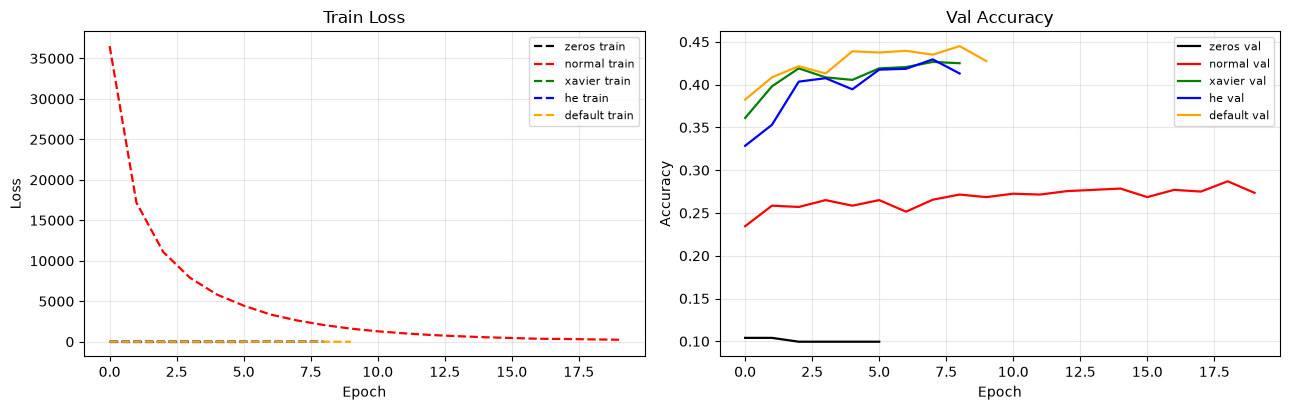

In [7]:
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

init_types = ['zeros', 'normal', 'xavier', 'he', 'default']   # 'default' — добавлено по заданию
histories = {}

for init in init_types:
    print(f'\n=== Инициализация: {init} ===')
    model = MLP(use_bn=False, dropout_rate=0.0, init_type=init).to(device)
    model, history, best_epoch = train_model(model, train_loader, val_loader, epochs=EPOCHS, patience=5, verbose=False)
    histories[init] = history
    print(f'Best val acc: {max(history["val_acc"]):.4f} | эпох: {len(history["val_acc"])} | {history["time"]:.0f} c')

# Визуализация
fig = make_subplots(rows=1, cols=2, subplot_titles=('Train Loss', 'Val Accuracy'))
colors = {'zeros':'black', 'normal':'red', 'xavier':'green', 'he':'blue', 'default':'orange'}
for init in init_types:
    fig.add_trace(go.Scatter(y=histories[init]['train_loss'], mode='lines', name=f'{init} train',
                              line=dict(color=colors[init], dash='dash')), row=1, col=1)
    fig.add_trace(go.Scatter(y=histories[init]['val_acc'], mode='lines', name=f'{init} val',
                              line=dict(color=colors[init])), row=1, col=2)
fig.update_xaxes(title_text='Epoch', row=1, col=1)
fig.update_xaxes(title_text='Epoch', row=1, col=2)
fig.update_yaxes(title_text='Loss', row=1, col=1)
fig.update_yaxes(title_text='Accuracy', row=1, col=2)
fig.show()
plotly_static(fig)   # статичная копия графика (видна без запущенного Jupyter)

In [8]:
# Почему 'zeros' не учится: градиенты скрытых слоёв при нулевой инициализации
torch.manual_seed(0)
m0 = MLP(init_type='zeros')
xb, yb = next(iter(train_loader))
F.cross_entropy(m0(xb), yb).backward()
for name, p in m0.named_parameters():
    if p.dim() == 2:
        print(f'{name:12s} норма градиента весов: {p.grad.norm():.4f}')

net.0.weight норма градиента весов: 0.0000
net.2.weight норма градиента весов: 0.0000
net.4.weight норма градиента весов: 0.0000
net.6.weight норма градиента весов: 0.0000


| инициализация | лучшая val acc | эпох до остановки | время |
|---|---|---|---|
| zeros | 0,104 | 6 | 6 с |
| normal (std = 1) | 0,287 | 20 (ранняя остановка не сработала) | 19 с |
| Xavier | 0,427 | 9 | 9 с |
| He | 0,430 | 9 | 9 с |
| по умолчанию (добавлено по заданию) | **0,445** | 10 | 10 с |

- **zeros** не обучается совсем: val acc 0,10 — уровень случайного угадывания 10 классов. Проверка показала, что при нулевых весах градиенты весов всех слоёв ровно 0. Все нейроны получают одинаковый нулевой сигнал, и обратное распространение не может их «развести». Меняться может только смещение выходного слоя, а по нему сеть способна выучить разве что частоты классов.
- **normal** обучается, но плохо. Начальная train loss около 36 000 (на графике), к 20-й эпохе она падает до сотен, а val acc держится на уровне 0,25–0,29. Ранняя остановка не сработала: val loss обновляла минимум хотя бы раз за каждые 5 эпох.
- **Xavier, He и инициализация по умолчанию** работают нормально, лучшая точность 0,43–0,445. Разница между ними 1,5–2 п. п., это 30–40 картинок из 2000 валидационных. На одном запуске с одним зерном такая разница ненадёжна.

**Сравнение с готовым выводом преподавателя (ниже).**
- Про zeros вывод подтвердился.
- Про normal — частично: потеря огромная, но в бесконечность не уходит, а постепенно снижается. Сеть просто остаётся на 15 п. п. позади остальных.
- «He немного лучше для ReLU» в этом запуске не подтвердилось: лучшей оказалась инициализация по умолчанию, He и Xavier почти равны. Инициализация PyTorch для `nn.Linear` по умолчанию — вариант равномерной инициализации Кайминга с границей $1/\sqrt{n_{in}}$, то есть она тоже масштабирует веса по числу входов. Поэтому она не хуже двух других.

**Вывод:** Нулевая инициализация даёт нулевые градиенты (веса не меняются), сеть не обучается. Normal (со стандартным отклонением 1) приводит к взрывным градиентам и loss уходит в бесконечность (на графике это видно). Xavier и He работают хорошо, He немного лучше для ReLU.

## Эксперимент 2: Влияние BatchNorm

Сравним сеть с BatchNorm и без. Используем лучшую инициализацию He.


=== BatchNorm: False ===


Early stopping at epoch 8
Best val acc: 0.4310 | эпох: 8 | 8 c

=== BatchNorm: True ===


Early stopping at epoch 8
Best val acc: 0.4460 | эпох: 8 | 10 c


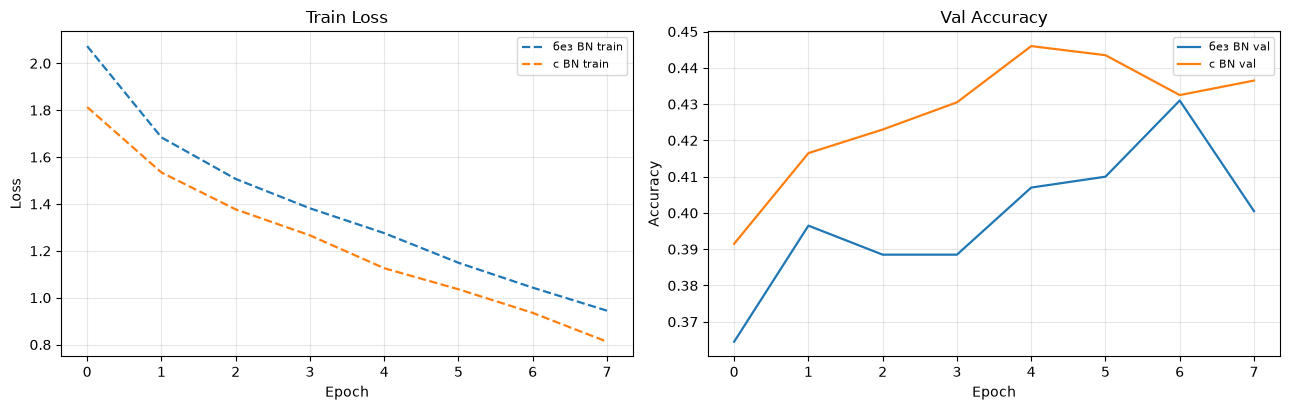

In [9]:
histories_bn = {}
for use_bn in [False, True]:
    print(f'\n=== BatchNorm: {use_bn} ===')
    model = MLP(use_bn=use_bn, dropout_rate=0.0, init_type='he').to(device)
    model, history, _ = train_model(model, train_loader, val_loader, epochs=EPOCHS, patience=5, verbose=False)
    histories_bn[use_bn] = history
    print(f'Best val acc: {max(history["val_acc"]):.4f} | эпох: {len(history["val_acc"])} | {history["time"]:.0f} c')

fig = make_subplots(rows=1, cols=2, subplot_titles=('Train Loss', 'Val Accuracy'))
fig.add_trace(go.Scatter(y=histories_bn[False]['train_loss'], mode='lines', name='без BN train', line=dict(dash='dash')), row=1, col=1)
fig.add_trace(go.Scatter(y=histories_bn[True]['train_loss'], mode='lines', name='с BN train', line=dict(dash='dash')), row=1, col=1)
fig.add_trace(go.Scatter(y=histories_bn[False]['val_acc'], mode='lines', name='без BN val'), row=1, col=2)
fig.add_trace(go.Scatter(y=histories_bn[True]['val_acc'], mode='lines', name='с BN val'), row=1, col=2)
fig.update_xaxes(title_text='Epoch'); fig.update_yaxes(title_text='Loss', row=1, col=1); fig.update_yaxes(title_text='Accuracy', row=1, col=2)
fig.show()
plotly_static(fig)   # статичная копия графика (видна без запущенного Jupyter)

С BatchNorm лучшая val acc 0,446, без него — 0,431 (+1,5 п. п.). Обе модели остановились на 8-й эпохе.

На графике train loss с BN ниже на каждой эпохе (на первой 1,81 против 2,07), и val acc с BN тоже выше на каждой эпохе. Цена — время: 10 с против 8 с, потому что BN добавляет вычисления в каждый слой.

Вывод преподавателя («BatchNorm ускоряет сходимость и часто даёт лучшее качество») подтверждается: ускорение видно с первой эпохи. Но обе модели переобучаются одинаково быстро. Train loss падает до 0,8–0,95, а лучшая точность достигнута на 5-й эпохе с BN и на 7-й без него, дальше val acc снижается. Регуляризующий эффект BN здесь незаметен — для этого в следующем эксперименте добавлен Dropout.

**Вывод:** BatchNorm ускоряет сходимость (кривая обучения падает быстрее) и часто даёт лучшее качество на валидации. Также может действовать как регуляризатор.

## Эксперимент 3: Влияние Dropout

Теперь добавим Dropout после скрытых слоёв. Сравним p=0.0, 0.3, 0.5. BatchNorm включим для всех вариантов (чтобы было стильно-модно-молодёжно).

**Задание**: попробуйте ещё несколько вариантов Dropout, в частности, больше 0.5, например, 1.


=== Dropout p=0.0 ===


Early stopping at epoch 10
Best val acc: 0.4470 | лучшая эпоха: 5 | min val loss: 1.6414 | train loss на лучшей эпохе: 1.1379

=== Dropout p=0.3 ===


Early stopping at epoch 15
Best val acc: 0.4665 | лучшая эпоха: 10 | min val loss: 1.5326 | train loss на лучшей эпохе: 1.3537

=== Dropout p=0.5 ===


Best val acc: 0.4640 | лучшая эпоха: 20 | min val loss: 1.5093 | train loss на лучшей эпохе: 1.4236

=== Dropout p=0.7 ===


Best val acc: 0.3945 | лучшая эпоха: 20 | min val loss: 1.6599 | train loss на лучшей эпохе: 1.7535

=== Dropout p=0.9 ===


Early stopping at epoch 6
Best val acc: 0.1690 | лучшая эпоха: 1 | min val loss: 2.2881 | train loss на лучшей эпохе: 4.0864

=== Dropout p=1.0 ===


Early stopping at epoch 6
Best val acc: 0.0945 | лучшая эпоха: 1 | min val loss: 181890.8455 | train loss на лучшей эпохе: 2.3027


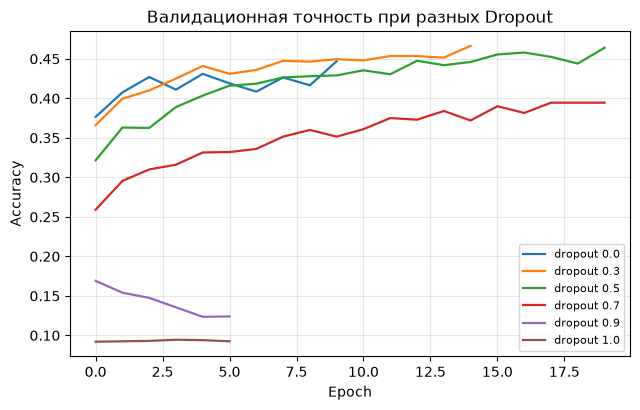

In [10]:
dropout_rates = [0.0, 0.3, 0.5, 0.7, 0.9, 1.0]   # 0.7, 0.9 и 1.0 — добавлены по заданию
histories_drop = {}

for p in dropout_rates:
    print(f'\n=== Dropout p={p} ===')
    model = MLP(use_bn=True, dropout_rate=p, init_type='he').to(device)
    model, history, best_ep = train_model(model, train_loader, val_loader, epochs=EPOCHS, patience=5, verbose=False)
    histories_drop[p] = history
    print(f'Best val acc: {max(history["val_acc"]):.4f} | лучшая эпоха: {best_ep + 1} | min val loss: {min(history["val_loss"]):.4f} | train loss на лучшей эпохе: {history["train_loss"][best_ep]:.4f}')

fig = go.Figure()
for p in dropout_rates:
    fig.add_trace(go.Scatter(y=histories_drop[p]['val_acc'], mode='lines', name=f'dropout {p}'))
fig.update_layout(title='Валидационная точность при разных Dropout', xaxis_title='Epoch', yaxis_title='Accuracy')
fig.show()
plotly_static(fig)   # статичная копия графика (видна без запущенного Jupyter)

| Dropout p | лучшая val acc | лучшая эпоха | min val loss | train loss на лучшей эпохе |
|---|---|---|---|---|
| 0,0 | 0,447 | 5 | 1,641 | 1,138 |
| 0,3 | **0,467** | 10 | 1,533 | 1,354 |
| 0,5 | 0,464 | 20 | **1,509** | 1,424 |
| 0,7 | 0,395 | 20 | 1,660 | 1,754 |
| 0,9 | 0,169 | 1 | 2,288 | 4,086 |
| 1,0 | 0,095 | 1 | 181 891 | 2,303 |

- **0,3 и 0,5 — лучшие и почти равные** (0,467 и 0,464, разница в 5 картинок). Без Dropout модель переобучается раньше всех: лучшая эпоха 5-я, train loss уже 1,14 при val loss 1,64, разрыв 0,50. С p = 0,3 разрыв 0,18, с p = 0,5 — 0,09, а лучшая эпоха сдвигается на 10-ю и 20-ю. Dropout делает то, для чего предназначен: сдерживает переобучение. При p = 0,5 модель ещё улучшалась на 20-й эпохе, то есть ей не хватило эпох.
- **p = 0,7 — уже недообучение.** Train loss на лучшей эпохе (1,75) *выше* val loss (1,66): сеть не успевает выучить даже обучающую выборку, точность падает до 0,395.
- **p = 0,9 — сеть почти не учится:** лучшая эпоха первая, точность 0,169. В каждом скрытом слое в среднем работает только один нейрон из десяти.
- **p = 1,0 (по заданию) — вырожденный случай.** При обучении Dropout обнуляет *все* выходы скрытых слоёв. На выход приходит только смещение последнего слоя, и train loss = 2,303 = ln 10 — ровно потеря при равномерном угадывании 10 классов. Веса второго и третьего слоёв градиентов не получают, потому что на их вход подаются нули. BatchNorm этих слоёв при обучении видит постоянный сигнал, и его накопленная дисперсия стремится к нулю. При проверке Dropout выключается, реальный сигнал проходит через необученные слои, и BatchNorm делит его на почти нулевую дисперсию. Активации взрываются: val loss 181 891, точность 0,095, то есть ниже случайной. Обучиться с p = 1 нельзя в принципе.

Вывод преподавателя («p = 0,3 даёт лучший результат») подтвердился с оговоркой: p = 0,5 практически не хуже по точности и лучше по val loss.

**Вывод:** Dropout помогает бороться с переобучением, особенно если сеть большая. При p=0.5 может быть некоторая потеря точности, но улучшение обобщения. Для нашего случая p=0.3 даёт лучший результат.

## Эксперимент 4: Влияние размера батча

Проверим, как размер батча влияет на сходимость и качество. Используем batch_size = 16, 64, 256. Фиксируем лучшие параметры: BN=True, dropout=0.3, he init.

**Задание**: попробуйте несколько размеров батчей и попробуйте найти наиболее эффективный для данной задачи.


=== Batch size = 16 ===


Best val acc: 0.4715 | эпох: 20 | 62 c, 3.1 c/эпоху

=== Batch size = 32 ===


Early stopping at epoch 17
Best val acc: 0.4745 | эпох: 17 | 28 c, 1.6 c/эпоху

=== Batch size = 64 ===


Early stopping at epoch 16
Best val acc: 0.4685 | эпох: 16 | 18 c, 1.1 c/эпоху

=== Batch size = 128 ===


Early stopping at epoch 15
Best val acc: 0.4650 | эпох: 15 | 13 c, 0.9 c/эпоху

=== Batch size = 256 ===


Early stopping at epoch 18
Best val acc: 0.4700 | эпох: 18 | 13 c, 0.7 c/эпоху


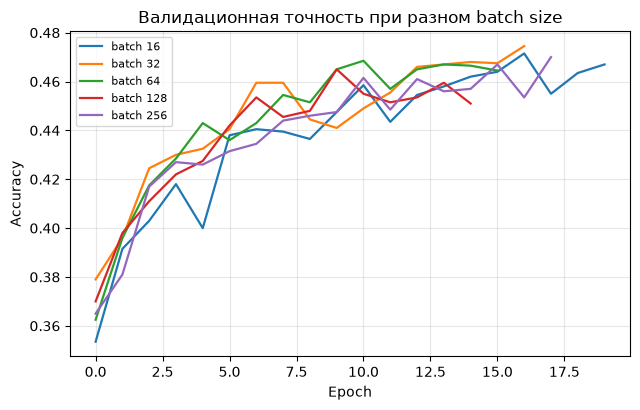

In [11]:
batch_sizes = [16, 32, 64, 128, 256]   # 32 и 128 — добавлены по заданию
histories_bs = {}

for bs in batch_sizes:
    print(f'\n=== Batch size = {bs} ===')
    train_loader_bs = DataLoader(train_dataset, batch_size=bs, shuffle=True)
    val_loader_bs = DataLoader(val_dataset, batch_size=bs, shuffle=False)
    model = MLP(use_bn=True, dropout_rate=0.3, init_type='he').to(device)
    model, history, _ = train_model(model, train_loader_bs, val_loader_bs, epochs=EPOCHS, patience=5, verbose=False)
    histories_bs[bs] = history
    print(f'Best val acc: {max(history["val_acc"]):.4f} | эпох: {len(history["val_acc"])} | {history["time"]:.0f} c, {history["time"] / len(history["val_acc"]):.1f} c/эпоху')

fig = go.Figure()
for bs in batch_sizes:
    fig.add_trace(go.Scatter(y=histories_bs[bs]['val_acc'], mode='lines', name=f'batch {bs}'))
fig.update_layout(title='Валидационная точность при разном batch size', xaxis_title='Epoch', yaxis_title='Accuracy')
fig.show()
plotly_static(fig)   # статичная копия графика (видна без запущенного Jupyter)

| батч | лучшая val acc | эпох | время всего | время на эпоху |
|---|---|---|---|---|
| 16 | 0,4715 | 20 | 62 с | 3,1 с |
| 32 | **0,4745** | 17 | 28 с | 1,6 с |
| 64 | 0,4685 | 16 | 18 с | 1,1 с |
| 128 | 0,4650 | 15 | 13 с | 0,9 с |
| 256 | 0,4700 | 18 | 13 с | 0,7 с |

**По точности все пять вариантов практически одинаковы:** от 0,465 до 0,4745, разброс меньше 1 п. п. (19 картинок из 2000). Это в пределах случайного разброса одного запуска.

**Время различается в 4,4 раза на эпоху:** от 3,1 с у батча 16 до 0,7 с у батча 256. Маленький батч — это много шагов оптимизатора за эпоху, и каждый шаг плохо загружает графический процессор (здесь MPS). Большой батч обрабатывается параллельно.

**Наиболее эффективный для этой задачи — батч 256 (или 128).** Точность та же, что у лучшего по val acc батча 32 (0,470 против 0,4745), а время 13 с вместо 28 с — и вместо 62 с у батча 16. Если нужна максимальная точность любой ценой — батч 32, но прибавка 0,45 п. п. здесь не стоит двукратного времени.

Вывод преподавателя («64 — неплохой баланс») в целом верен. Но на этом оборудовании и с этой сетью можно брать батч крупнее: качество не страдает, а скорость растёт.

**Вывод:** Меньший батч (16) даёт более шумные градиенты, но может быстрее сходиться и лучше обобщать. Большой батч (256) обучается стабильнее, но может хуже обобщать. Здесь 64 даёт неплохой баланс.

## Эксперимент 5: Аугментация данных (горизонтальное отражение)

Добавим простое преобразование: случайное горизонтальное отражение. Сравним с базовым вариантом (без аугментации). Используем лучшие параметры: BN, dropout=0.3, batch_size=64, he init.

**Задание**: добавить отражение вокруг горизонтально оси (спросить у LLM).

Best val acc with augmentation: 0.4860


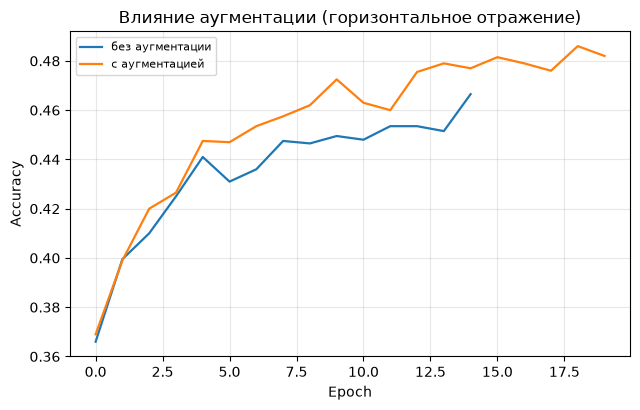

In [12]:
# Определим трансформацию с аугментацией
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),  # случайное отражение
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

transform_val = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

# Создадим датасеты с новой трансформацией
train_aug = datasets.CIFAR10(DATA, train=True, download=True, transform=transform_train)
val_aug = datasets.CIFAR10(DATA, train=True, download=True, transform=transform_val)

# Используем те же индексы подвыборки
train_aug_sub = Subset(train_aug, train_indices)
val_aug_sub = Subset(val_aug, val_indices)

train_loader_aug = DataLoader(train_aug_sub, batch_size=64, shuffle=True)
val_loader_aug = DataLoader(val_aug_sub, batch_size=64, shuffle=False)

# Обучим модель с аугментацией
model_aug = MLP(use_bn=True, dropout_rate=0.3, init_type='he').to(device)
model_aug, history_aug, _ = train_model(model_aug, train_loader_aug, val_loader_aug, epochs=EPOCHS, patience=5, verbose=False)
print(f'Best val acc with augmentation: {max(history_aug["val_acc"]):.4f}')

# Для сравнения возьмём историю без аугментации (из предыдущего эксперимента с bs=64, dropout=0.3)
history_no_aug = histories_drop[0.3]  # но там bs=64, BN=True? Да, в histories_drop для p=0.3 мы использовали BN и batch 64.

fig = go.Figure()
fig.add_trace(go.Scatter(y=history_no_aug['val_acc'], mode='lines', name='без аугментации'))
fig.add_trace(go.Scatter(y=history_aug['val_acc'], mode='lines', name='с аугментацией'))
fig.update_layout(title='Влияние аугментации (горизонтальное отражение)', xaxis_title='Epoch', yaxis_title='Accuracy')
fig.show()
plotly_static(fig)   # статичная копия графика (видна без запущенного Jupyter)

Best val acc with vertical flip: 0.4515


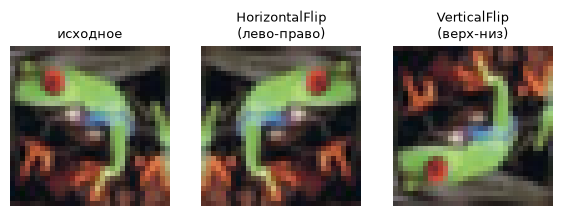

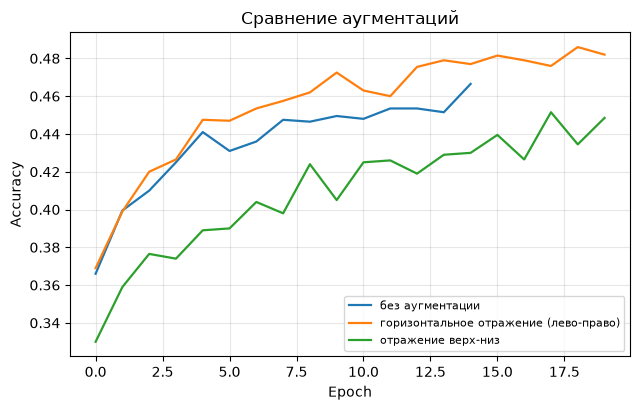

In [13]:
# Задание: отражение относительно горизонтальной оси (верх <-> низ) — transforms.RandomVerticalFlip
transform_train_v = transforms.Compose([
    transforms.RandomVerticalFlip(),   # случайное отражение «вверх ногами» с вероятностью 0.5
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])
train_vaug_sub = Subset(datasets.CIFAR10(DATA, train=True, download=True, transform=transform_train_v), train_indices)
train_loader_vaug = DataLoader(train_vaug_sub, batch_size=64, shuffle=True)

model_vaug = MLP(use_bn=True, dropout_rate=0.3, init_type='he').to(device)
model_vaug, history_vaug, _ = train_model(model_vaug, train_loader_vaug, val_loader_aug, epochs=EPOCHS, patience=5, verbose=False)
print(f'Best val acc with vertical flip: {max(history_vaug["val_acc"]):.4f}')

# Пример того, что видит сеть при каждом виде аугментации
img0 = datasets.CIFAR10(DATA, train=True).data[int(train_indices[0])]
fig, axes = plt.subplots(1, 3, figsize=(7, 2.6))
for ax, (im, t) in zip(axes, [(img0, 'исходное'), (img0[:, ::-1], 'HorizontalFlip\n(лево-право)'), (img0[::-1], 'VerticalFlip\n(верх-низ)')]):
    ax.imshow(im); ax.set_title(t, fontsize=9); ax.axis('off')
plt.show()

fig = go.Figure()
fig.add_trace(go.Scatter(y=history_no_aug['val_acc'], mode='lines', name='без аугментации'))
fig.add_trace(go.Scatter(y=history_aug['val_acc'], mode='lines', name='горизонтальное отражение (лево-право)'))
fig.add_trace(go.Scatter(y=history_vaug['val_acc'], mode='lines', name='отражение верх-низ'))
fig.update_layout(title='Сравнение аугментаций', xaxis_title='Epoch', yaxis_title='Accuracy')
fig.show()
plotly_static(fig)   # статичная копия графика (видна без запущенного Jupyter)

| вариант | лучшая val acc | точность на тесте |
|---|---|---|
| без аугментации (BN, Dropout 0,3 из эксперимента 3) | 0,4665 | — |
| горизонтальное отражение (лево ↔ право) | **0,486** | **0,504** |
| отражение относительно горизонтальной оси (верх ↔ низ), по заданию | 0,4515 | 0,4615 |

Отражение относительно горизонтальной оси — это переворот картинки «вверх ногами». В torchvision это `RandomVerticalFlip`: название дано по направлению, в котором переставляются пиксели, а не по оси. Примеры перевёрнутых картинок — на рисунке выше.

- **Отражение лево-право** добавило 2 п. п. к лучшей val acc. На графике его кривая выше базовой почти на всех эпохах после пятой, и за 20 эпох ранняя остановка не сработала. Зеркальная копия самолёта, кошки или грузовика — тоже правдоподобное изображение того же класса. Выборка фактически удвоилась без потери смысла, и модель переобучается позже.
- **Отражение верх-низ ухудшило результат:** −1,5 п. п. к базовому варианту на валидации и −4,3 п. п. к лево-правому отражению на тесте. В CIFAR-10 нет перевёрнутых самолётов и кошек: небо всегда сверху, земля и вода снизу, и для MLP, который опирается на расположение цветовых пятен, это сильная подсказка. После такой аугментации половина обучающих картинок неправдоподобна. Модель тратит ёмкость на устойчивость к перевороту, которая на тесте не нужна, и теряет подсказку о положении.

Аугментация полезна, только если преобразование не меняет класс и даёт картинки, похожие на реальные данные. Вывод преподавателя («аугментация улучшает обобщающую способность») верен для лево-правого отражения, но не для любой аугментации.

**Вывод:** Аугментация данных (даже простое отражение) улучшает обобщающую способность модели, так как искусственно расширяет обучающую выборку и добавляет инвариантность к ориентации.

## Эксперимент 6: Комбинация лучших практик + Early Stopping

Теперь соберём всё вместе: He инициализация, BatchNorm, dropout=0.3, batch_size=64, аугментация, и добавим early stopping с patience=7. Обучим до 50 эпох и посмотрим, когда остановится.

In [14]:
best_model = MLP(use_bn=True, dropout_rate=0.3, init_type='he').to(device)
best_model, history_best, best_epoch = train_model(best_model, train_loader_aug, val_loader_aug,
                                                    epochs=S(50, 2), lr=0.001, patience=7, verbose=True)

print(f'\nОбучение остановлено на эпохе {best_epoch+1} с лучшей валидационной точностью: {max(history_best["val_acc"]):.4f}')

# Финальное тестирование
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
best_model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = best_model(inputs)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
test_acc = correct / total
print(f'Test accuracy: {test_acc:.4f}')

Epoch 1/50 | Train Loss: 2.1149 | Val Loss: 1.7737 | Val Acc: 0.3575


Epoch 2/50 | Train Loss: 1.8546 | Val Loss: 1.6850 | Val Acc: 0.3940


Epoch 3/50 | Train Loss: 1.7354 | Val Loss: 1.6266 | Val Acc: 0.4340


Epoch 4/50 | Train Loss: 1.6866 | Val Loss: 1.6000 | Val Acc: 0.4265


Epoch 5/50 | Train Loss: 1.6290 | Val Loss: 1.5720 | Val Acc: 0.4365


...

Epoch 25/50 | Train Loss: 1.1991 | Val Loss: 1.4635 | Val Acc: 0.4845


Epoch 26/50 | Train Loss: 1.1992 | Val Loss: 1.4119 | Val Acc: 0.4955


Epoch 27/50 | Train Loss: 1.1677 | Val Loss: 1.4036 | Val Acc: 0.4970


Epoch 28/50 | Train Loss: 1.1534 | Val Loss: 1.4439 | Val Acc: 0.4950
Early stopping at epoch 28

Обучение остановлено на эпохе 21 с лучшей валидационной точностью: 0.5025


Test accuracy: 0.5077


**Задача**: получилось ли повысить точность выше 0.5109?

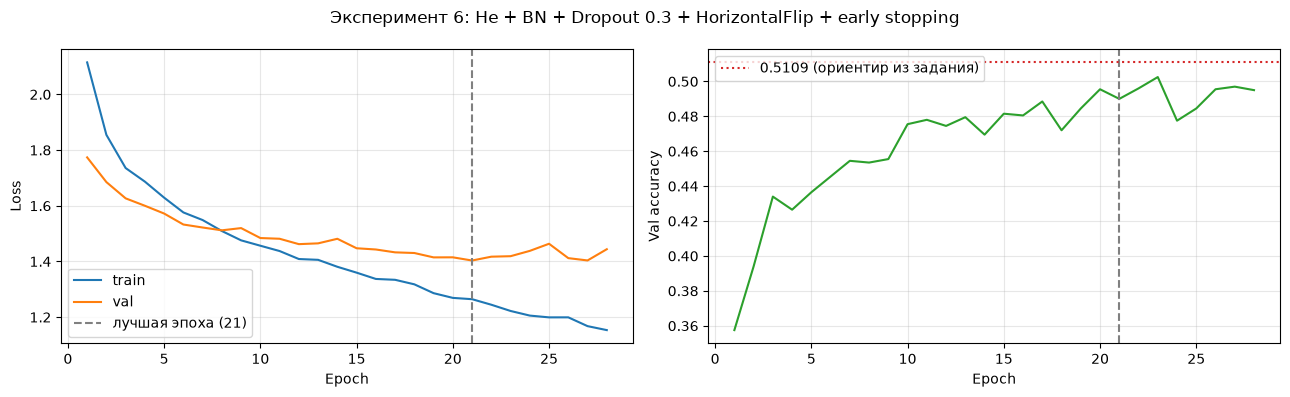

Тест, итоговая модель (эксперимент 6): 0.5077


Тест, модель с аугментацией из эксперимента 5: 0.5043


Тест, модель с отражением верх-низ: 0.4615


In [15]:
# Для ответа: кривые итогового обучения и сравнение с моделями из экспериментов 3 и 5 на тестовой выборке
def test_accuracy(model):
    model.eval(); correct = 0
    with torch.no_grad():
        for x, y in DataLoader(test_dataset, batch_size=256):
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(test_dataset)

ep = range(1, len(history_best['val_acc']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ep, history_best['train_loss'], label='train'); axes[0].plot(ep, history_best['val_loss'], label='val')
axes[0].axvline(best_epoch + 1, color='gray', ls='--', label=f'лучшая эпоха ({best_epoch + 1})')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, history_best['val_acc'], color='C2'); axes[1].axvline(best_epoch + 1, color='gray', ls='--')
axes[1].axhline(0.5109, color='C3', ls=':', label='0.5109 (ориентир из задания)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Val accuracy'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.suptitle('Эксперимент 6: He + BN + Dropout 0.3 + HorizontalFlip + early stopping')
plt.tight_layout(); plt.show()

print(f"Тест, итоговая модель (эксперимент 6): {test_acc:.4f}")
print(f"Тест, модель с аугментацией из эксперимента 5: {test_accuracy(model_aug):.4f}")
print(f"Тест, модель с отражением верх-низ: {test_accuracy(model_vaug):.4f}")

**Нет, превысить 0,5109 не получилось: на тесте 0,5077**, на 0,32 п. п. ниже (32 картинки из 10 000). Это практически тот же уровень: стандартная ошибка оценки точности на 10 000 картинках около 0,5 п. п., больше этой разницы.

**Как шло обучение итоговой модели** (He, BatchNorm, Dropout 0,3, батч 64, отражение лево-право, ранняя остановка с `patience = 7`):
- val loss снижалась до 21-й эпохи (минимум 1,403);
- затем 7 эпох без улучшения, остановка на 28-й эпохе, веса взяты с 21-й;
- лучшая val acc 0,5025 была на 23-й эпохе.

На графике после 21-й эпохи train loss продолжает падать (1,26 → 1,15), а val loss — уже нет. Начинается переобучение, и ранняя остановка его отсекла.

**Сравнение на тесте:**
- итоговая модель — 0,5077;
- модель с отражением из эксперимента 5 (до 20 эпох, `patience = 5`) — 0,5043;
- модель с отражением верх-низ — 0,4615.

Сочетание всех приёмов и более терпеливая ранняя остановка добавили всего 0,3 п. п. к модели из эксперимента 5. Похоже, для MLP на 10 000 картинках CIFAR-10 это близко к пределу: каждая регуляризация даёт 1–2 п. п., а дальше всё упирается в архитектуру. Полносвязная сеть не знает, что соседние пиксели связаны, и не умеет находить один и тот же признак в разных местах картинки. Это задача свёрточных сетей (практика 6).

**Итог:** Мы получили модель, которая с помощью комбинации регуляризационных техник показывает лучший результат на тесте. Для MLP на CIFAR-10 точность около 45-50% — это нормально (полносвязные сети не очень подходят для изображений). Главное — мы увидели, как каждый метод влияет на процесс обучения.

😊 **Шутка:** Теперь вы знаете, как укротить даже такую сложную зверушку, как CIFAR-10, с помощью простого MLP и магии регуляризации. Дальше — сверточные сети, где точность будет гораздо выше!

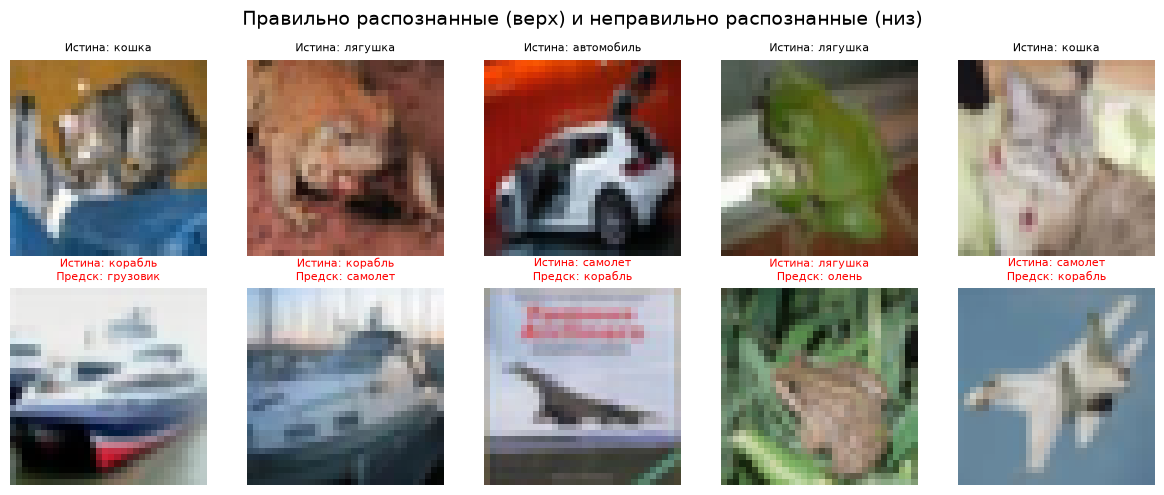

In [16]:
# Функция для денормализации изображения
def denormalize(img_tensor):
    mean = np.array([0.4914, 0.4822, 0.4465])
    std = np.array([0.247, 0.243, 0.261])
    img = img_tensor.numpy().transpose(1, 2, 0)  # (C, H, W) -> (H, W, C)
    img = img * std + mean
    img = np.clip(img, 0, 1)
    return img

# Функция для отображения примеров правильных и неправильных предсказаний
def show_predictions(model, test_loader, class_names, device, num_examples=5):
    model.eval()
    correct_examples = []
    wrong_examples = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for i in range(images.size(0)):
                if preds[i] == labels[i]:
                    if len(correct_examples) < num_examples:
                        correct_examples.append((images[i].cpu(), labels[i].cpu(), preds[i].cpu()))
                else:
                    if len(wrong_examples) < num_examples:
                        wrong_examples.append((images[i].cpu(), labels[i].cpu(), preds[i].cpu()))

            if len(correct_examples) >= num_examples and len(wrong_examples) >= num_examples:
                break

    # Отображение
    fig, axes = plt.subplots(2, num_examples, figsize=(12, 5))
    fig.suptitle('Правильно распознанные (верх) и неправильно распознанные (низ)', fontsize=14)

    for i in range(num_examples):
        # Правильные
        img, label, pred = correct_examples[i]
        ax = axes[0, i]
        ax.imshow(denormalize(img))
        ax.set_title(f'Истина: {class_names[label]}', fontsize=8)
        ax.axis('off')

        # Неправильные
        img, label, pred = wrong_examples[i]
        ax = axes[1, i]
        ax.imshow(denormalize(img))
        ax.set_title(f'Истина: {class_names[label]}\nПредск: {class_names[pred]}', fontsize=8, color='red')
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Пример использования:
class_names = ['самолет', 'автомобиль', 'птица', 'кошка', 'олень', 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
show_predictions(best_model, test_loader, class_names, device, num_examples=5)

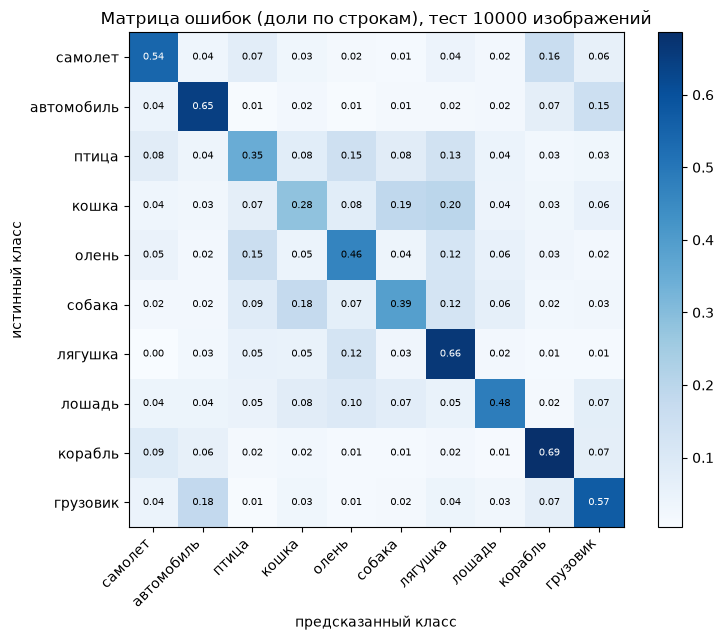

Точность по классам: {'самолет': 0.544, 'автомобиль': 0.646, 'птица': 0.348, 'кошка': 0.283, 'олень': 0.463, 'собака': 0.39, 'лягушка': 0.664, 'лошадь': 0.483, 'корабль': 0.686, 'грузовик': 0.57}


In [17]:
# Какие классы MLP путает чаще всего: матрица ошибок итоговой модели на тесте
from sklearn.metrics import confusion_matrix
best_model.eval()
preds, ys = [], []
with torch.no_grad():
    for x, y in DataLoader(test_dataset, batch_size=512):
        preds.append(best_model(x.to(device)).argmax(1).cpu()); ys.append(y)
preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
cm = confusion_matrix(ys, preds, normalize='true', labels=range(10))
plt.figure(figsize=(8, 6.5))
plt.imshow(cm, cmap='Blues')
for i in range(10):
    for j in range(10):
        plt.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if cm[i, j] > 0.5 else 'black')
plt.xticks(range(10), class_names, rotation=45, ha='right'); plt.yticks(range(10), class_names)
plt.xlabel('предсказанный класс'); plt.ylabel('истинный класс'); plt.colorbar(fraction=0.046)
plt.title(f'Матрица ошибок (доли по строкам), тест {len(ys)} изображений')
plt.tight_layout(); plt.show()
print('Точность по классам:', {c: round(float(cm[i, i]), 3) for i, c in enumerate(class_names)})

## Выводы по практике

1. **Инициализация** — обязательное условие обучения, а не тонкая настройка. Нулевая не обучается вовсе (0,10), normal с std = 1 застревает на 0,29. Все инициализации, масштабированные по числу входов (Xavier, He, по умолчанию PyTorch), дают 0,43–0,445.
2. **BatchNorm** ускоряет обучение (потеря ниже с первой эпохи) и добавил 1,5 п. п., но от переобучения не спасает.
3. **Dropout** — главный регуляризатор для этого MLP. При p = 0,3–0,5 точность выше почти на 2 п. п., а разрыв между train loss и val loss в 3–6 раз меньше. Слишком сильный Dropout (p ≥ 0,7) приводит к недообучению, при p = 1 обучение невозможно.
4. **Размер батча** почти не влияет на точность (разброс меньше 1 п. п.), но сильно влияет на время: эпоха с батчем 256 в 4,4 раза быстрее, чем с батчем 16.
5. **Аугментация** работает, только если она правдоподобна: отражение лево-право +2 п. п., верх-низ −1,5 п. п.
6. **Итог:** сочетание всех приёмов дало 0,5077 на тесте, планка 0,5109 не превышена.

**Где модель ошибается** (примеры предсказаний и матрица ошибок итоговой модели на тесте):
- Лучше всего распознаются корабль (0,686), лягушка (0,664), автомобиль (0,646) и грузовик (0,57).
- Хуже всего — кошка (0,283), птица (0,348) и собака (0,39).
- Основные путаницы: кошка → лягушка (0,20) и собака (0,19), собака → кошка (0,18), грузовик ↔ автомобиль (0,18 и 0,15), самолёт → корабль (0,16).

Путаются классы с похожими фоном, цветом и формой: голубое небо и вода у самолёта и корабля, похожие машины, похожие окрас и поза у кошек и собак. Судя по этим путаницам, MLP опирается в основном на цвет и фон, а не на форму объекта. Поэтому около 50 % — естественный уровень для полносвязной сети на CIFAR-10, и следующий шаг — свёрточные сети.